# Experiment 030: N=4 group-size ablation at 7B

3 registered seeds. Seeds 0 and 2 have matched N=8 and N=4 endpoints. Seed 1 reached the exact a2 viability sentinel at step 100, so it is shown as a stopped arm and is not included in endpoint inference.

In [7]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / 'config.py').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

RES = ROOT / 'results'
FIG = ROOT / 'analysis' / 'figures' / '030_1'
FIG.mkdir(parents=True, exist_ok=True)

def jload(path):
    with open(path) as handle:
        return json.load(handle)

def save(fig, name):
    fig.savefig(FIG / f'{name}.png', dpi=300, bbox_inches='tight')

family = jload(RES / '030_family_summary.json')
pairs = {row['seed']: row for row in family['pairs']}
runs = {}
for seed in range(3):
    n8_dir = RES / f'013_COLAB_FULL_B7_sft_grpo_seed{seed}'
    n4_dir = RES / f'030_COLAB_FULL_B7_external_sft_grpo_seed{seed}'
    runs[seed] = {
        'n8_dir': n8_dir,
        'n4_dir': n4_dir,
        'n8_eval': jload(n8_dir / 'grpo_eval.json'),
        'n8_log': pd.DataFrame(jload(n8_dir / 'grpo_trainlog.json')),
        'n4_log': pd.DataFrame(jload(n4_dir / 'grpo_trainlog.json')),
    }
    if pairs[seed]['status'] == 'completed':
        runs[seed]['n4_eval'] = jload(n4_dir / 'grpo_eval.json')

COMPLETED = [seed for seed, row in pairs.items() if row['status'] == 'completed']
GROUPS = ('overall', 'easy', 'medium', 'hard')
LABELS = ('Overall', 'Easy', 'Medium', 'Hard')
SEED_COLORS = {0: '#4C78A8', 1: '#E45756', 2: '#54A24B'}
SIZE_COLORS = {'N=8': '#4C78A8', 'N=4': '#F58518'}
plt.style.use('seaborn-v0_8-whitegrid')
print('figures ->', FIG.relative_to(ROOT))


figures -> analysis/figures/030_1


## Outcomes and endpoints

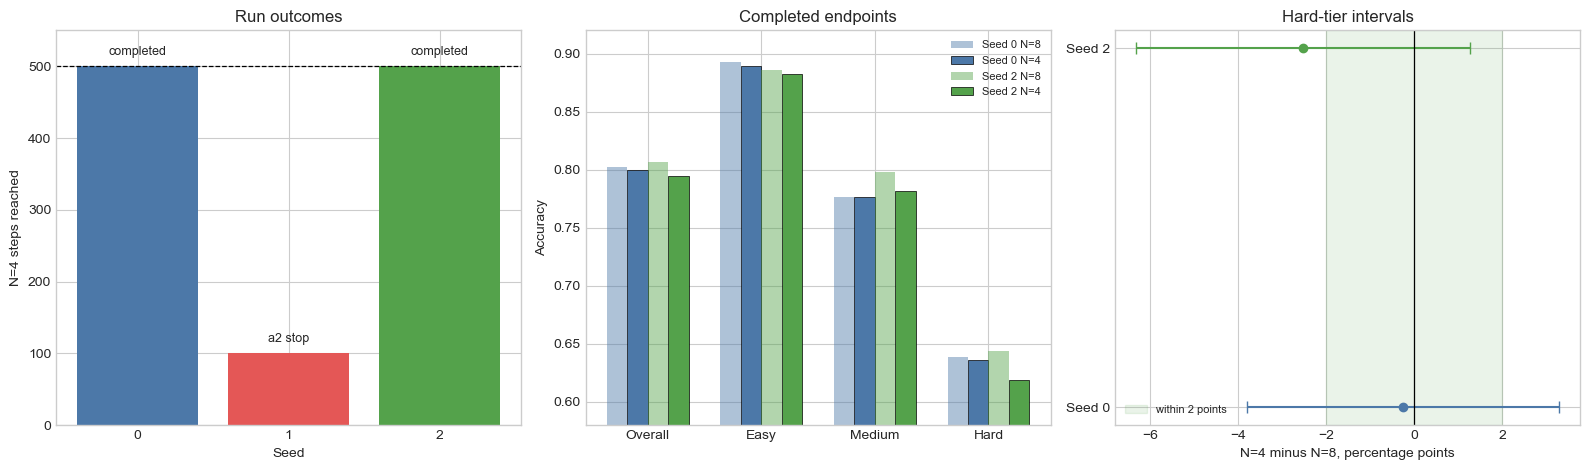

,status,N=4 last step,N=8 hard,N=4 hard,hard delta
seed,,,,,
0,completed,500,0.6389,0.6364,-0.0025
1,viability_gate_failure,100,NaN,NaN,NaN
2,completed,500,0.6439,0.6187,-0.0253


N=8     N=4   delta  ci_low  ci_high
seed group                                           
0    overall  0.8020  0.7999 -0.0021 -0.0133   0.0090
     easy     0.8931  0.8896 -0.0034 -0.0159   0.0091
     medium   0.7767  0.7767  0.0000 -0.0164   0.0164
     hard     0.6389  0.6364 -0.0025 -0.0379   0.0328
2    overall  0.8068  0.7946 -0.0122 -0.0234  -0.0011
     easy     0.8862  0.8828 -0.0034 -0.0148   0.0080
     medium   0.7980  0.7816 -0.0164 -0.0361   0.0033
     hard     0.6439  0.6187 -0.0253 -0.0631   0.0126

In [8]:
outcome_rows = []
for seed in range(3):
    pair = pairs[seed]
    n4_log = runs[seed]['n4_log']
    row = {
        'seed': seed,
        'status': pair['status'],
        'N=4 last step': int(n4_log['step'].max()),
        'N=8 hard': pair.get('tiers', {}).get('hard', {}).get('n8_acc', np.nan),
        'N=4 hard': pair.get('tiers', {}).get('hard', {}).get('n4_acc', np.nan),
        'hard delta': pair.get('tiers', {}).get('hard', {}).get('delta', np.nan),
    }
    outcome_rows.append(row)
outcome_tbl = pd.DataFrame(outcome_rows).set_index('seed')

endpoint_rows = []
for seed in COMPLETED:
    for group in GROUPS:
        row = pairs[seed]['tiers'][group]
        endpoint_rows.append({
            'seed': seed,
            'group': group,
            'N=8': row['n8_acc'],
            'N=4': row['n4_acc'],
            'delta': row['delta'],
            'ci_low': row['ci'][0],
            'ci_high': row['ci'][1],
        })
endpoint_tbl = pd.DataFrame(endpoint_rows)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

steps = outcome_tbl['N=4 last step']
bars = axes[0].bar(steps.index.astype(str), steps, color=[SEED_COLORS[s] for s in steps.index])
axes[0].axhline(500, color='black', lw=0.9, ls='--')
axes[0].set_ylim(0, 550)
axes[0].set_xlabel('Seed')
axes[0].set_ylabel('N=4 steps reached')
axes[0].set_title('Run outcomes')
for bar, seed in zip(bars, steps.index):
    label = 'completed' if seed in COMPLETED else 'a2 stop'
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 12,
                 label, ha='center', va='bottom', fontsize=9)

x = np.arange(len(GROUPS))
width = 0.18
offsets = [-1.5, -0.5, 0.5, 1.5]
labels = []
for offset, (seed, size) in zip(offsets, [(0, 'N=8'), (0, 'N=4'), (2, 'N=8'), (2, 'N=4')]):
    values = [endpoint_tbl.query('seed == @seed and group == @group')[size].iloc[0] for group in GROUPS]
    label = f'Seed {seed} {size}'
    labels.append(label)
    axes[1].bar(x + offset * width, values, width, label=label,
                color=SEED_COLORS[seed], alpha=1.0 if size == 'N=4' else 0.45,
                edgecolor='black' if size == 'N=4' else None, linewidth=0.5)
axes[1].set_xticks(x)
axes[1].set_xticklabels(LABELS)
axes[1].set_ylim(0.58, 0.92)
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Completed endpoints')
axes[1].legend(fontsize=8)

y = np.arange(len(COMPLETED))
for i, seed in enumerate(COMPLETED):
    row = endpoint_tbl.query("seed == @seed and group == 'hard'").iloc[0]
    delta = row['delta'] * 100
    low = (row['delta'] - row['ci_low']) * 100
    high = (row['ci_high'] - row['delta']) * 100
    axes[2].errorbar(delta, i, xerr=[[low], [high]], fmt='o', color=SEED_COLORS[seed], capsize=4)
axes[2].axvspan(-2, 2, color='#54A24B', alpha=0.12, label='within 2 points')
axes[2].axvline(0, color='black', lw=0.9)
axes[2].set_yticks(y)
axes[2].set_yticklabels([f'Seed {seed}' for seed in COMPLETED])
axes[2].set_xlabel('N=4 minus N=8, percentage points')
axes[2].set_title('Hard-tier intervals')
axes[2].legend(fontsize=8)

fig.tight_layout()
save(fig, 'fig01_endpoint_comparison')
plt.show()
display(outcome_tbl.round(4))
display(endpoint_tbl.set_index(['seed', 'group']).round(4))


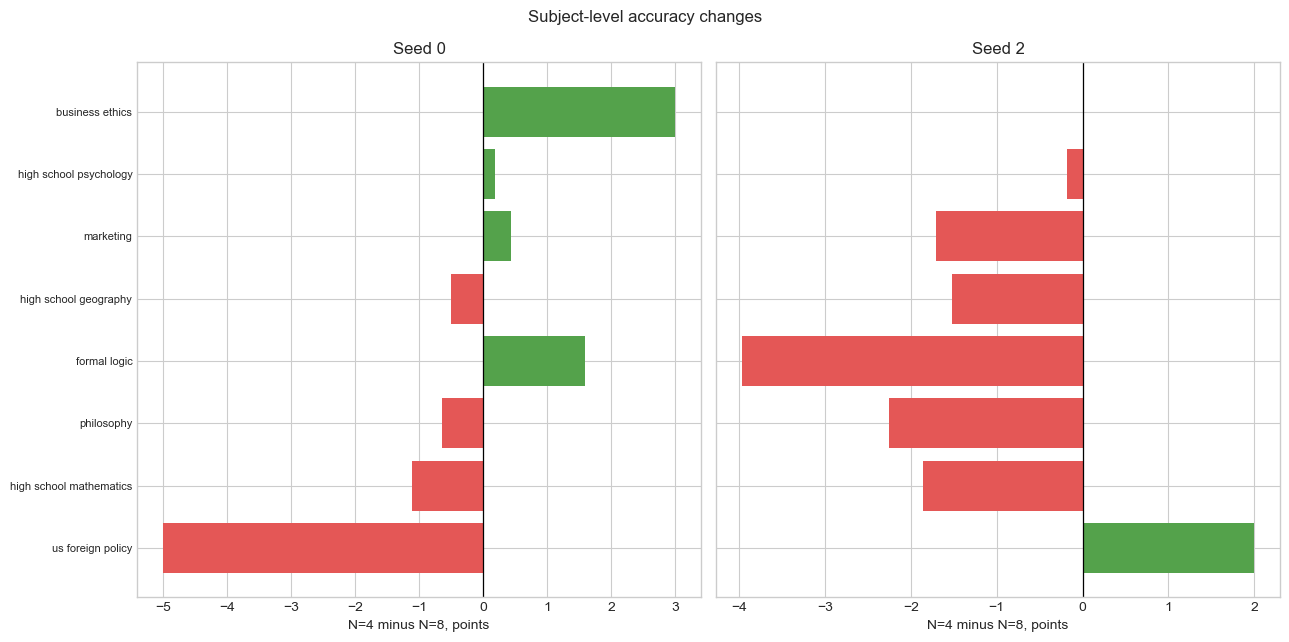

In [9]:
subject_rows = []
for seed in COMPLETED:
    n8 = runs[seed]['n8_eval']['per_subject_acc']
    n4 = runs[seed]['n4_eval']['per_subject_acc']
    for subject in n8:
        subject_rows.append({
            'seed': seed,
            'subject': subject,
            'N=8': n8[subject],
            'N=4': n4[subject],
            'delta': n4[subject] - n8[subject],
        })
subject_tbl = pd.DataFrame(subject_rows)
order = subject_tbl.groupby('subject')['delta'].mean().sort_values().index

fig, axes = plt.subplots(1, len(COMPLETED), figsize=(13, 6.5), sharey=True)
for ax, seed in zip(axes, COMPLETED):
    rows = subject_tbl.query('seed == @seed').set_index('subject').loc[order]
    colors = ['#54A24B' if value >= 0 else '#E45756' for value in rows['delta']]
    ax.barh(np.arange(len(rows)), rows['delta'] * 100, color=colors)
    ax.axvline(0, color='black', lw=0.9)
    ax.set_title(f'Seed {seed}')
    ax.set_xlabel('N=4 minus N=8, points')
axes[0].set_yticks(np.arange(len(order)))
axes[0].set_yticklabels([name.replace('_', ' ') for name in order], fontsize=8)
fig.suptitle('Subject-level accuracy changes')
fig.tight_layout()
save(fig, 'fig02_subject_changes')
plt.show()


## Training dynamics

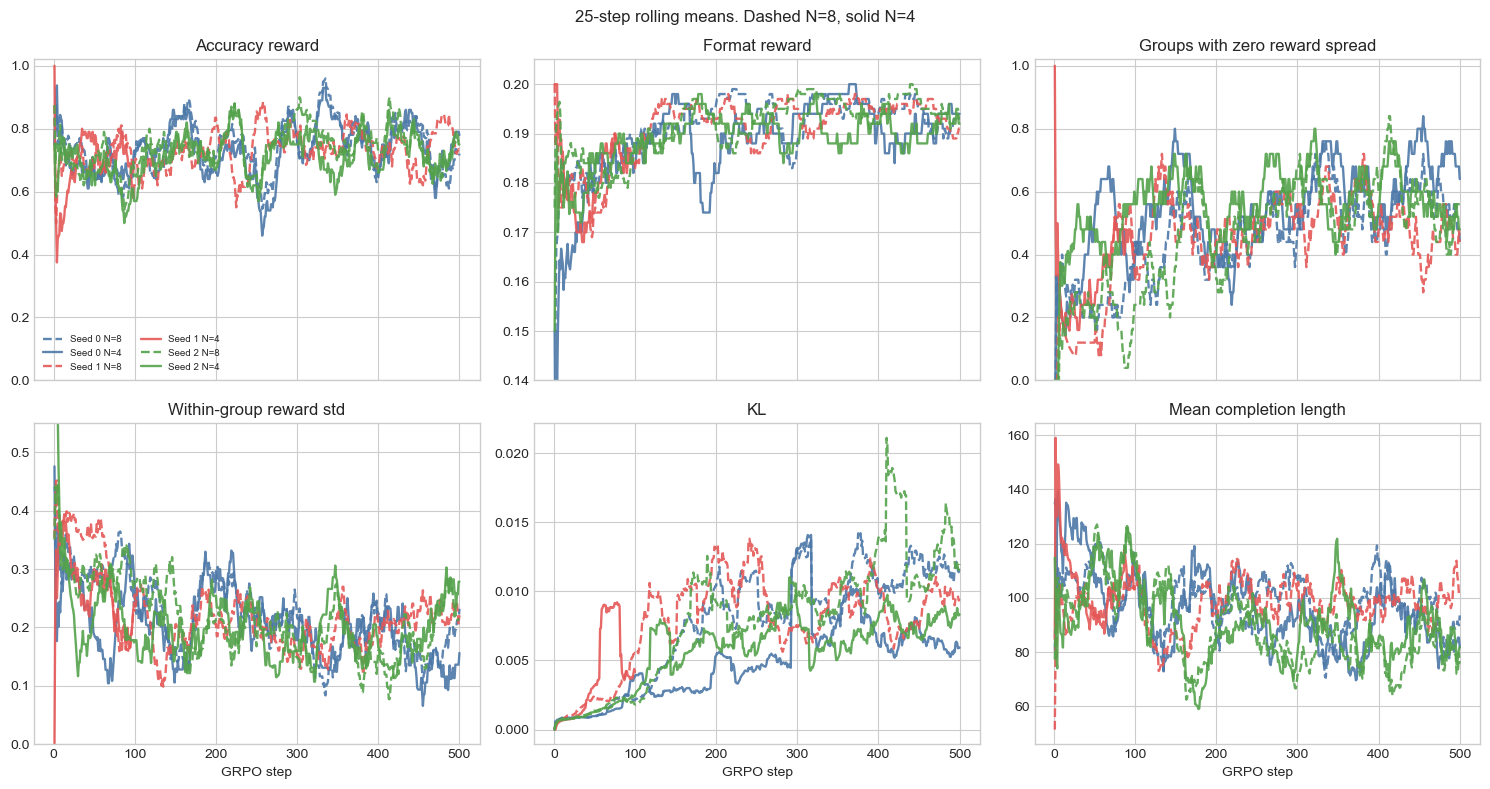

In [10]:
metrics = [
    ('rewards/accuracy_reward/mean', 'Accuracy reward', (0, 1.02)),
    ('rewards/format_reward/mean', 'Format reward', (0.14, 0.205)),
    ('frac_reward_zero_std', 'Groups with zero reward spread', (0, 1.02)),
    ('reward_std', 'Within-group reward std', (0, 0.55)),
    ('kl', 'KL', None),
    ('completions/mean_length', 'Mean completion length', None),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
for ax, (metric, title, ylim) in zip(axes.flat, metrics):
    for seed in range(3):
        for size, style in [('n8', '--'), ('n4', '-')]:
            frame = runs[seed][f'{size}_log']
            rows = frame.dropna(subset=['step', metric]).set_index('step')[metric]
            smooth = rows.rolling(25, min_periods=1).mean()
            ax.plot(smooth.index, smooth, color=SEED_COLORS[seed], ls=style,
                    lw=1.7, alpha=0.9, label=f'Seed {seed} N={size[-1]}')
    ax.set_title(title)
    if ylim:
        ax.set_ylim(*ylim)
for ax in axes[1]:
    ax.set_xlabel('GRPO step')
axes[0, 0].legend(ncol=2, fontsize=7)
fig.suptitle('25-step rolling means. Dashed N=8, solid N=4')
fig.tight_layout()
save(fig, 'fig03_training_dynamics')
plt.show()


## Measured cost

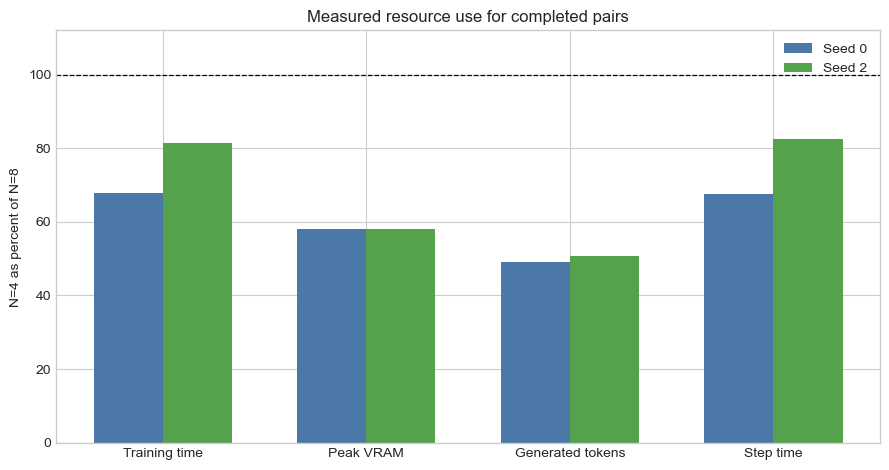

status  training hours  peak VRAM GiB  generated tokens  \
seed group size                                                               
0    N=8         completed            2.97          71.32          844743.0   
     N=4         completed            2.01          41.38          414964.0   
1    N=4           a2 stop            0.69          40.15           87136.0   
2    N=8         completed            2.43          70.99          804734.0   
     N=4         completed            1.98          41.17          407668.0   

                 mean step seconds  logged steps  
seed group size                                   
0    N=8                     20.52           500  
     N=4                     13.84           500  
1    N=4                     15.83           100  
2    N=8                     16.51           500  
     N=4                     13.63           500

In [11]:
cost_rows = []
for seed in range(3):
    pair = pairs[seed]
    if pair['status'] == 'completed':
        for size in ('n8', 'n4'):
            dynamics = pair['dynamics'][size]
            cost_rows.append({
                'seed': seed,
                'group size': f'N={size[-1]}',
                'status': 'completed',
                'training hours': pair['training_seconds'][size] / 3600,
                'peak VRAM GiB': pair['peak_vram_gib'][size],
                'generated tokens': dynamics['total_generated_tokens'],
                'mean step seconds': dynamics['step_time']['mean'],
                'logged steps': dynamics['logged_steps'],
            })
    else:
        log = runs[seed]['n4_log']
        record = pair['a2_record']
        cost_rows.append({
            'seed': seed,
            'group size': 'N=4',
            'status': 'a2 stop',
            'training hours': record['elapsed_sec'] / 3600,
            'peak VRAM GiB': record['peak_vram_gib'],
            'generated tokens': log['num_tokens'].max() if 'num_tokens' in log else np.nan,
            'mean step seconds': log['step_time'].mean(),
            'logged steps': int(log['step'].max()),
        })
cost_tbl = pd.DataFrame(cost_rows)

relative_rows = []
for seed in COMPLETED:
    rows = cost_tbl.query('seed == @seed').set_index('group size')
    relative_rows.append({
        'seed': seed,
        'Training time': rows.loc['N=4', 'training hours'] / rows.loc['N=8', 'training hours'] * 100,
        'Peak VRAM': rows.loc['N=4', 'peak VRAM GiB'] / rows.loc['N=8', 'peak VRAM GiB'] * 100,
        'Generated tokens': rows.loc['N=4', 'generated tokens'] / rows.loc['N=8', 'generated tokens'] * 100,
        'Step time': rows.loc['N=4', 'mean step seconds'] / rows.loc['N=8', 'mean step seconds'] * 100,
    })
relative_tbl = pd.DataFrame(relative_rows).set_index('seed')

fig, ax = plt.subplots(figsize=(9, 4.8))
x = np.arange(len(relative_tbl.columns))
width = 0.34
for i, seed in enumerate(COMPLETED):
    ax.bar(x + (i - 0.5) * width, relative_tbl.loc[seed], width,
           label=f'Seed {seed}', color=SEED_COLORS[seed])
ax.axhline(100, color='black', lw=0.9, ls='--')
ax.set_xticks(x)
ax.set_xticklabels(relative_tbl.columns)
ax.set_ylabel('N=4 as percent of N=8')
ax.set_ylim(0, 112)
ax.set_title('Measured resource use for completed pairs')
ax.legend()
fig.tight_layout()
save(fig, 'fig04_resource_use')
plt.show()
display(cost_tbl.set_index(['seed', 'group size']).round(2))


## Exact values

In [12]:
family_rows = []
for pair in family['pairs']:
    row = {'seed': pair['seed'], 'status': pair['status']}
    if pair['status'] == 'completed':
        row.update({
            'hard N=8': pair['tiers']['hard']['n8_acc'],
            'hard N=4': pair['tiers']['hard']['n4_acc'],
            'hard delta': pair['tiers']['hard']['delta'],
            'hard CI low': pair['tiers']['hard']['ci'][0],
            'hard CI high': pair['tiers']['hard']['ci'][1],
            'hard raw p': pair['hard_raw_p'],
            'overall delta': pair['tiers']['overall']['delta'],
            'probe delta': pair['probe']['delta'],
        })
    else:
        row['last step'] = pair['a2_record']['end_step']
    family_rows.append(row)
family_tbl = pd.DataFrame(family_rows).set_index('seed')

dynamics_rows = []
for seed in COMPLETED:
    for size, values in pairs[seed]['dynamics'].items():
        for metric in ('frac_reward_zero_std', 'reward_std',
                       'rewards/accuracy_reward/mean', 'rewards/format_reward/mean',
                       'kl', 'completions/mean_length', 'step_time'):
            dynamics_rows.append({'seed': seed, 'group size': f'N={size[-1]}',
                                  'metric': metric, **values[metric]})
dynamics_tbl = pd.DataFrame(dynamics_rows)

outcome_tbl.to_csv(FIG / 'run_outcomes.csv')
endpoint_tbl.to_csv(FIG / 'endpoint_comparison.csv', index=False)
subject_tbl.to_csv(FIG / 'subject_changes.csv', index=False)
cost_tbl.to_csv(FIG / 'measured_cost.csv', index=False)
dynamics_tbl.to_csv(FIG / 'training_dynamics_summary.csv', index=False)
family_tbl.to_csv(FIG / 'family_summary.csv')

display(family_tbl.round(4))
print('family status:', family['status'])
print('Holm binding:', family['holm_binding'])
print('hard delta mean:', family['descriptive_summary']['hard_delta_mean'])
print('hard delta range:', family['descriptive_summary']['hard_delta_range'])


,status,hard N=8,hard N=4,hard delta,hard CI low,hard CI high,hard raw p,overall delta,probe delta,last step
seed,,,,,,,,,,
0,completed,0.6389,0.6364,-0.0025,-0.0379,0.0328,1.0000,-0.0021,-0.0027,NaN
1,viability_gate_failure,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.0
2,completed,0.6439,0.6187,-0.0253,-0.0631,0.0126,0.2451,-0.0122,0.0000,NaN


family status: descriptive_incomplete
Holm binding: False
hard delta mean: -0.013888888888888888
hard delta range: [-0.025252525252525252, -0.0025252525252525255]


## Cross-referenced conclusion

My package finished as planned, but it didn't produce three completed endpoints. Seed 1 reached the exact a2 viability sentinel at step 100, while seeds 0 and 2 completed all 500 steps. This leaves two matched pairs, so the registered Holm family analysis and a common three-seed reading are not valid.

For hard accuracy, N = 4 changed by -0.25 points in seed 0 and -2.53 points in seed 2. The mean across two completed pairs is -1.39 points, with both intervals crossing zero. This is descriptive evidence that N=4 can reach a similar endpoint at lower cost, but it is not formal equivalence. The seed-1 a2 stop also shows that the smaller group was not equally reliable across all three seeds.